# Introduction to domain adaptation with `skada`

Authors: [Pedro L. C. Rodrigues](https://plcrodrigues.github.io) and [Thomas Moreau](https://tommoral.github.io)

<img src="figures/skada_logo.png" width="400">

---

## Table of contents

* [1. Introduction](#introduction)
* [2. Methods for unsupervised domain adaptation](#methods)
    * [2.1 Reweighting](#methods_reweighting)
    * [2.2 Mapping](#methods_mapping)
    * [2.3 End-to-end deep learning](#methods_deep)
* [3. A running example: visual comparison of DA methods](#example)
* [4. Evaluating DA methods without target labels](#evaluating)
    * [4.1 Prediction Entropy](#evaluating_entropy)
    * [4.2 Circular Validation](#evaluating_circular)
* [5. Building DA pipelines with `make_da_pipeline`](#pipelines)
    * [5.1 Estimators vs. Adapters](#pipelines_adapters)
    * [5.2 The `Shared` vs `PerDomain` distinction](#pipelines_shared)
    * [5.3 Reweighting methods and `set_fit_request`](#pipelines_reweighting)
* [6. Hyperparameter selection with `GridSearchCV`](#gridsearch)
* [7. An example with real data](#realdata)

## 1. Introduction <a class="anchor" id="introduction"></a> [↑](#Table-of-contents)

Domain adaptation is a subfield of machine learning that tackles a fundamental challenge: **models trained on one data distribution often fail when deployed in a different but related setting**. 

This performance drop is caused by a **dataset shift** between the labelled *source* domain used for training and the unlabelled *target* domain encountered at inference time. 

Such shifts are very common in practice :
- a computer vision model trained on synthetic images may struggle on real photographs
- a medical classifier trained on data from one hospital may underperform at another due to differences in equipment or patient demographics,
- a speech recognition system trained in a quiet studio may degrade in noisy environments. 

Domain adaptation methods aim to bridge this gap, leveraging the unlabelled target data to adapt the model without requiring expensive target annotations. 

Formally, we denote by $X$ the input features and $y$ the associated labels; the source and target domains are respectively characterised by joint distributions $P^s(X, y)$ and $P^t(X, y)$, which are assumed to differ. 

The distributional mismatch, broadly called *dataset shift*, can take four forms:

- **Covariate shift**: the marginal input distribution changes $P^s(X) \neq P^t(X)$ while the class-conditional relationship remains intact $P^s(y|X) = P^t(y|X)$.

- **Target shift**: the label marginal changes $P^s(y) \neq P^t(y)$ while the class-conditional feature distribution is preserved $P^s(X|y) = P^t(X|y)$.

- **Conditional shift**: the class-conditional distributions themselves differ across domains $P^s(y|X) \neq P^t(y|X)$ or $P^s(X|y) \neq P^t(X|y)$.

- **Subspace shift**: although $P^s(X) \neq P^t(X)$, there exists a projection $W$ such that $P^s(WX) = P^t(WX)$, meaning the shift can be corrected by moving to a lower-dimensional subspace.

The [`skada`](https://scikit-adaptation.github.io/) package provides a unified, scikit-learn-compatible implementation of a wide range of domain adaptation methods.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
import sklearn
sklearn.set_config(enable_metadata_routing=True)

%matplotlib inline

In [3]:
!pip install skada

Let's start by creating a simulated dataset using `skada`.

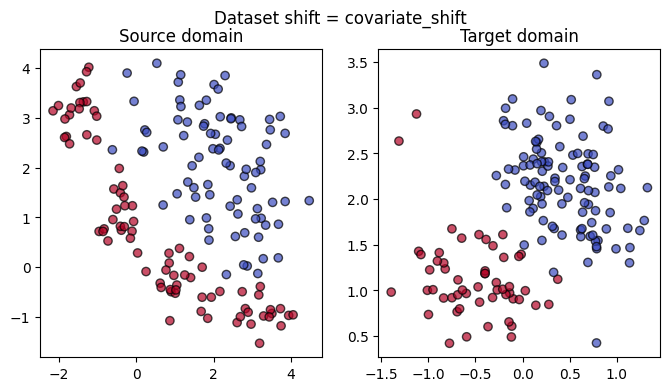

In [4]:
from skada import source_target_split
from skada.datasets import make_shifted_datasets

import matplotlib.pyplot as plt

random_state = 42

shift = 'covariate_shift'

X, y, sample_domain = make_shifted_datasets(
    n_samples_source=20,
    n_samples_target=20,
    shift=shift,
    noise=0.3,
    label="binary",
    random_state=random_state,
)

X_source, X_target, y_source, y_target = source_target_split(
    X, y, sample_domain=sample_domain)

fig, ax = plt.subplots(figsize=(8, 4), ncols=2)
fig.suptitle(f'Dataset shift = {shift}')
ax[0].scatter(X_source[:, 0], X_source[:, 1], c=y_source, cmap="coolwarm", edgecolor="k", alpha=0.7)
ax[0].set_title("Source domain")
ax[1].scatter(X_target[:, 0], X_target[:, 1], c=y_target, cmap="coolwarm", edgecolor="k", alpha=0.7)
ax[1].set_title("Target domain")
plt.show()

<div class="alert alert-success">
    <b>EXERCISE</b>:
     <ul>
         <li>How would you proceed to determine the type of shift of a given pair of source-target datasets? (suppose that you know labels Y on both domains)</li>
         <br>
         <li>Apply your proposal to the datasets stored in dataset_exercise.pkl and determine which kind of shift we have.
     </ul>
</div>

With full access to $(X_t, y_t)$ you can directly estimate and compare all the relevant distributions:

- **Covariate shift**: compare $P^s(X)$ vs $P^t(X)$ with MMD. Then train a classifier on source and check that its accuracy on target. If the score is similar, then $P^s(y|X) \approx P^t(y|X)$. Otherwise, we have covariate shift.

- **Target shift**: compare empirical label frequencies $P^s(y)$ vs $P^t(y)$ directly via a histogram comparison. Verify if $P^s(X|y) \approx P^t(X|y)$ by comparing class-conditional feature distributions class by class.

- **Conditional shift**: train a classifier on source and one on target, and compare their outputs on the same inputs. If $P^s(y|X)$ and $P^t(y|X)$ differ noticeably while $P^s(y) \approx P^t(y)$, you have conditional shift.

- **Subspace shift**: run PCA or CCA on the combined data and check whether source and target align in a low-dimensional projection even if they differ globally. If the shift is concentrated along only a few principal components, subspace shift is a good candidate.

In most practical cases, however, **target labels are unavailable** — annotating target data is precisely what we want to avoid. This setting is known as *unsupervised domain adaptation*, and it is the one we focus on throughout this notebook. As a consequence, diagnosing which type of dataset shift is at play becomes significantly harder, since we can no longer directly compare class-conditional distributions or label marginals on the target side.

---
## 2. Methods for unsupervised domain adaptation <a class="anchor" id="methods"></a> [↑](#Table-of-contents)

In the unsupervised DA setting, the goal is to leverage the unlabelled target data $\{x_i^t\}$ to improve the classifier trained on the labelled source $\{(x_i^s, y_i^s)\}$. 

Three main families of methods exist, each addressing the problem from a different angle.

### 2.1 Reweighting <a class="anchor" id="methods_reweighting"></a> [↑](#Table-of-contents)

The idea is to reweight the source samples during training so that the weighted empirical distribution $\sum_i w_i \delta_{x_i^s}$ better resembles the target $P^t(X)$. The adapted classifier minimises:

$$\hat{f} = \arg\min_{f} \frac{1}{n_s} \sum_{i=1}^{n_s} w_i \, \ell(f(x_i^s), y_i^s)$$

where the weights $w_i \propto P^t(x_i^s) / P^s(x_i^s)$ are estimated from the data. This is well-motivated under **covariate shift** and **target shift**, where the decision boundary is the same across domains.

### 2.2 Mapping <a class="anchor" id="methods_mapping"></a> [↑](#Table-of-contents)

Rather than reweighting, mapping methods learn a transformation $m$ that maps the source data into the target distribution, so that the adapted source and target become indistinguishable. 

The classifier is then trained on the mapped source:

$$\hat{f} = f \circ m$$

Optimal Transport (OT) is the most principled way to compute such a mapping: it finds the transport plan $\gamma$ that moves source mass towards the target at minimum cost. 

This is well-suited for **conditional shift**, where the features themselves need to be transformed.

### 2.3 End-to-end deep learning <a class="anchor" id="methods_deep"></a> [↑](#Table-of-contents)

Deep DA methods jointly learn a feature extractor $g$ and a classifier $f$ such that the extracted features are both discriminative for the task and domain-invariant. 

This is done by adding a DA regularisation term to the training loss:

$$\mathcal{L} = \sum_{i=1}^{n_s} \ell_{CE}\Big(f(g(x_i^s)), y_i^s\Big) + \lambda \sum_{i,j} \ell_{DA}\Big(g(x_i^s), g(x_j^t)\Big)$$

where $\ell_{DA}$ can be an adversarial loss (DANN), an MMD distance (DAN), or an OT distance (DeepJDOT). 

These methods are the most flexible and can handle complex shifts, but require more data and computation.

---
## 3. A running example: visual comparison of DA methods <a class="anchor" id="example"></a> [↑](#Table-of-contents)

Let's generate a dataset with a **conditional shift** and compare the three families of methods visually.

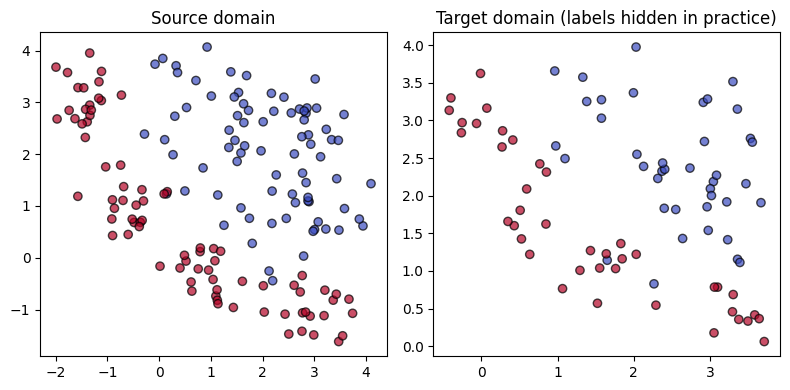

In [5]:
from skada.datasets import make_shifted_datasets
from skada import source_target_split

random_state = 42

X, y, sample_domain = make_shifted_datasets(
    n_samples_source=20,
    n_samples_target=10,
    shift='conditional_shift',
    noise=0.3,
    label='binary',
    random_state=random_state,
)

X_source, X_target, y_source, y_target = source_target_split(
    X, y, sample_domain=sample_domain
)

# --- plot source and target side by side ---
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].scatter(X_source[:, 0], X_source[:, 1], c=y_source, cmap='coolwarm', edgecolor='k', alpha=0.7)
axes[0].set_title('Source domain')
axes[1].scatter(X_target[:, 0], X_target[:, 1], c=y_target, cmap='coolwarm', edgecolor='k', alpha=0.7)
axes[1].set_title('Target domain (labels hidden in practice)')
plt.tight_layout()
plt.show()

In [6]:
# Helper: plot decision boundary on target
import numpy as np

def plot_decision_boundary(estimator, X_source, y_source, X_target, y_target, title, ax):
    h = 0.05
    X_all = np.vstack([X_source, X_target])
    x_min, x_max = X_all[:, 0].min() - 0.5, X_all[:, 0].max() + 0.5
    y_min, y_max = X_all[:, 1].min() - 0.5, X_all[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
    grid = np.c_[xx.ravel(), yy.ravel()]
    # predict on target domain (sample_domain = -1)
    sd_grid = -np.ones(len(grid), dtype=int)
    Z = estimator.predict(grid, sample_domain=sd_grid)
    Z = Z.reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
    ax.scatter(X_target[:, 0], X_target[:, 1], c=y_target, cmap='coolwarm', edgecolor='k', alpha=0.8)
    acc = np.mean(estimator.predict(X_target, sample_domain=-np.ones(len(X_target), dtype=int)) == y_target)
    ax.set_title(f'{title}\n(target acc = {acc:.2f})')

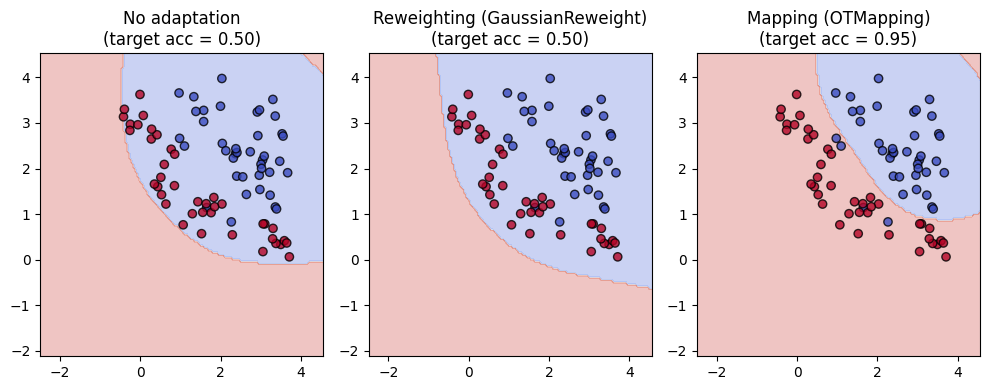

In [7]:
from sklearn.svm import SVC
from skada import (
    GaussianReweight,       # reweighting
    OTMapping,              # mapping
)

fig, axes = plt.subplots(1, 3, figsize=(10, 4))

# --- No adaptation baseline ---
baseline = SVC()
baseline.fit(X_source, y_source)
# plot manually for baseline (no sample_domain needed)
h = 0.05
X_all = np.vstack([X_source, X_target])
x_min, x_max = X_all[:, 0].min() - 0.5, X_all[:, 0].max() + 0.5
y_min, y_max = X_all[:, 1].min() - 0.5, X_all[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))
Z = baseline.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
axes[0].contourf(xx, yy, Z, alpha=0.3, cmap='coolwarm')
axes[0].scatter(X_target[:, 0], X_target[:, 1], c=y_target, cmap='coolwarm', edgecolor='k', alpha=0.8)
acc_base = np.mean(baseline.predict(X_target) == y_target)
axes[0].set_title(f'No adaptation\n(target acc = {acc_base:.2f})')

# --- Reweighting ---
rw = GaussianReweight(SVC().set_fit_request(sample_weight=True))
rw.fit(X, y, sample_domain=sample_domain)
plot_decision_boundary(rw, X_source, y_source, X_target, y_target, 'Reweighting (GaussianReweight)', axes[1])

# --- Mapping ---
ot = OTMapping(SVC().set_fit_request(sample_weight=True))
ot.fit(X, y, sample_domain=sample_domain)
plot_decision_boundary(ot, X_source, y_source, X_target, y_target, 'Mapping (OTMapping)', axes[2])

plt.tight_layout()
plt.show()

Visual inspection gives useful intuition, but it is not a reliable way to compare methods or select hyperparameters — especially as data dimensionality grows. We need **quantitative metrics**.

---
## 4. Evaluating DA methods without target labels <a class="anchor" id="evaluating"></a> [↑](#Table-of-contents)

In the unsupervised setting, we have no target labels to evaluate our model directly. Standard cross-validation on the target is therefore off the table. 

Instead, `skada` provides **DA scorers**: proxy metrics that estimate target performance using only the unlabelled target data.

We present two complementary scorers here.

### 4.1 Prediction Entropy <a class="anchor" id="evaluating_entropy"></a> [↑](#Table-of-contents)

The intuition is simple: a well-adapted model should make **confident** predictions on the target — the class probability distributions should be peaked rather than flat. 

We therefore use the (negative) entropy of predictions on target as a proxy score:

$$\text{score} = -\frac{1}{n_t} \sum_{j=1}^{n_t} H(f(x_j^t))$$

where $H$ is the Shannon entropy. Higher score (lower entropy) is better. This scorer is cheap, assumption-light, but can be fooled by a confidently wrong model.

### 4.2 Circular Validation <a class="anchor" id="evaluating_circular"></a> [↑](#Table-of-contents)

The idea is to validate adaptation quality indirectly using the known source labels. The procedure has four steps:

1. Train a DA model on source → predict pseudo-labels on target.

2. Train a *reverse* DA model from target (using pseudo-labels).

3. Predict on the labelled source data.

4. Score against the true source labels.

If the original adaptation was good, the domains are well-aligned and the reverse adaptation should also work well. 

This scorer tends to be more reliable than entropy because it anchors on the ground-truth source labels.

> **Note**: `skada` also implements `ImportanceWeightedScorer`, `SoftNeighborhoodDensity`, `DeepEmbeddedValidation`, `MixValScorer`, and `MaNoScorer`. See the [documentation](https://scikit-adaptation.github.io/all.html#module-skada.metrics) for a full overview.

In [8]:
from skada import OTMapping
from skada.metrics import PredictionEntropyScorer, CircularValidation
from sklearn.model_selection import cross_val_score, ShuffleSplit
from sklearn.svm import SVC

estimator = OTMapping(SVC(probability=True))
cv = ShuffleSplit(n_splits=5, test_size=0.3, random_state=random_state)

from skada.model_selection import SourceTargetShuffleSplit

# Prediction Entropy
scores_pe = cross_val_score(
    estimator, X, y,
    params={'sample_domain': sample_domain},
    cv=cv,
    scoring=PredictionEntropyScorer(),
)
print(f"Prediction Entropy score: {scores_pe.mean():.3f} ± {scores_pe.std():.3f}")

# Circular Validation
scores_cv = cross_val_score(
    estimator, X, y,
    params={'sample_domain': sample_domain},
    cv=cv,
    scoring=CircularValidation(),
)
print(f"Circular Validation score:  {scores_cv.mean():.3f} ± {scores_cv.std():.3f}")

Prediction Entropy score: -0.104 ± 0.008
Circular Validation score:  0.938 ± 0.052


<div class="alert alert-success">
    <b>EXERCISE</b>: Is ShuffleSplit really appropriate for handling the cross-validation? Check the proportions of the souce/target domains in each split.
</div>

<div class="alert alert-success">
    <b>EXERCISE</b>: Compare the two scorers across the three methods from Section 3 (no adaptation, reweighting, mapping). Do they agree on which method is best?
</div>

---
## 5. Building DA pipelines with `make_da_pipeline` <a class="anchor" id="pipelines"></a> [↑](#Table-of-contents)

`skada` is designed to fit naturally into the scikit-learn ecosystem. The key building block is `make_da_pipeline`, which works like sklearn's `make_pipeline` but is domain-aware: at fit time, preprocessing steps see both source and target data, while the final classifier only sees source data (with labels).

### 5.1 Estimators vs. Adapters <a class="anchor" id="pipelines_adapters"></a> [↑](#Table-of-contents)

So far we used `skada` methods as self-contained estimators, e.g. `OTMapping(SVC())`, where the DA logic and the classifier are bundled together. 

`skada` also exposes each method as a standalone **adapter** — e.g. `OTMappingAdapter()` — that can be inserted into a pipeline alongside any sklearn classifier.

The [adapter](https://scikit-adaptation.github.io/quickstart.html#adapter) plays the role of a domain-aware transformer: at fit time it has access to both source and target data and computes the adaptation (transport plan, reweighting coefficients, subspace projection, etc.). It then transforms the source features before passing them to the downstream classifier, which trains on the adapted data as usual.

In [9]:
from skada import OTMappingAdapter, make_da_pipeline
from sklearn.svm import SVC

pipeline = make_da_pipeline(
    OTMappingAdapter(),  # computes and applies the OT mapping
    SVC(),               # trains on adapted source features
)
pipeline.fit(X, y, sample_domain=sample_domain)

,steps,"[('otmappingadapter', ...), ('svc', ...)]"
,transform_input,None
,memory,None
,verbose,False
,base_estimator,OTMappingAdapter()
,max_iter,100000
,metric,'sqeuclidean'
,norm,None
,metric,'sqeuclidean'
,norm,None
,max_iter,100000


This separation is useful because it lets you freely combine any adapter with any sklearn-compatible classifier, and it composes naturally with preprocessing steps — which brings us to the next point.

### 5.2 The `Shared` vs `PerDomain` distinction <a class="anchor" id="pipelines_shared"></a> [↑](#Table-of-contents)

When you add a standard sklearn transformer (e.g. `StandardScaler`) to a DA pipeline, there is an important question: should it be fitted on the pooled source+target data, or separately on each domain?

- **Shared** (default): fits the transformer on all data jointly. Useful when you want a single shared representation space.

- **PerDomain**: fits a separate instance of the transformer per domain. Useful when domains have very different scales or distributions — e.g. you want to standardise each domain independently before applying the DA adapter.

A plain `StandardScaler()` in `make_da_pipeline` behaves as `Shared` by default.

In [ ]:
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from skada import OTMappingAdapter, make_da_pipeline, PerDomain

# Option A: shared scaler (fitted on source + target jointly)
pipeline_shared = make_da_pipeline(
    StandardScaler(),       # Shared by default
    OTMappingAdapter(),
    SVC(),
)

# Option B: per-domain scaler (fitted separately on source and target)
pipeline_per_domain = make_da_pipeline(
    PerDomain(StandardScaler()),
    OTMappingAdapter(),
    SVC(),
)

pipeline_shared.fit(X, y, sample_domain=sample_domain)
pipeline_per_domain.fit(X, y, sample_domain=sample_domain)

,steps,"[('perdomain_standardscaler', ...), ('otmappingadapter', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,base_estimator,StandardScaler()
,copy,True
,with_mean,True
,with_std,True
,copy,True
,with_mean,True
,with_std,True


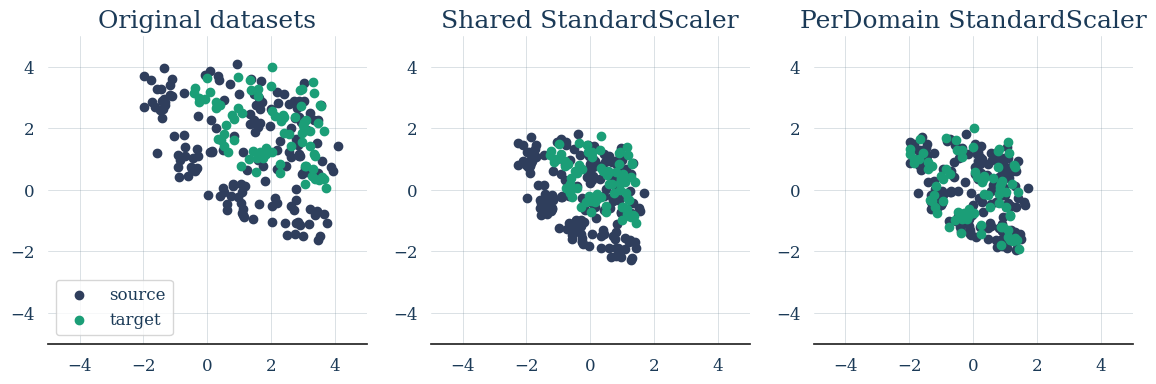

In [43]:
random_state = 42

X, y, sample_domain = make_shifted_datasets(
    n_samples_source=20,
    n_samples_target=10,
    shift='conditional_shift',
    noise=0.3,
    label='binary',
    random_state=random_state,
)

X_source, X_target, y_source, y_target = source_target_split(
    X, y, sample_domain=sample_domain
)

pipe_shared = make_da_pipeline(
    StandardScaler(),
)
pipe_shared.fit(X, y, sample_domain=sample_domain)
X_shared = pipe_shared.transform(X)

pipe_per = make_da_pipeline(
    PerDomain(StandardScaler()),
)
pipe_per.fit(X, y, sample_domain=sample_domain)
X_per = pipe_per.transform(X, sample_domain=sample_domain)

# --- plot source and target side by side ---
fig, ax = plt.subplots(figsize=(14, 4), ncols=3)

ax[0].scatter(X[sample_domain==1, 0], X[sample_domain==1, 1], c='C0', label='source')
ax[0].scatter(X[sample_domain==-2, 0], X[sample_domain==-2, 1], c='C1', label='target')
ax[0].set_title('Original datasets')

ax[1].scatter(X_shared[sample_domain==1, 0], X_shared[sample_domain==1, 1], c='C0')
ax[1].scatter(X_shared[sample_domain==-2, 0], X_shared[sample_domain==-2, 1], c='C1')
ax[1].set_title('Shared StandardScaler')

ax[2].scatter(X_per[sample_domain==1, 0], X_per[sample_domain==1, 1], c='C0')
ax[2].scatter(X_per[sample_domain==-2, 0], X_per[sample_domain==-2, 1], c='C1')
ax[2].set_title('PerDomain StandardScaler')

ax[0].legend()
for axi in ax:
    axi.set_xlim([-5, +5])
    axi.set_ylim([-5, +5])
plt.show()

### 5.3 Reweighting methods and `set_fit_request` <a class="anchor" id="pipelines_reweighting"></a> [↑](#Table-of-contents)

For reweighting adapters, the adapter computes per-sample weights that need to be passed to the downstream classifier. 

sklearn estimators don't accept `sample_weight` by default — you need to explicitly opt in using `set_fit_request`:

In [ ]:
from sklearn.linear_model import LogisticRegression
from skada import GaussianReweightAdapter, make_da_pipeline

pipeline_rw = make_da_pipeline(
    GaussianReweightAdapter(),
    LogisticRegression().set_fit_request(sample_weight=True),  # opt-in to sample_weight
)

pipeline_rw.fit(X, y, sample_domain=sample_domain)

---
## 6. Hyperparameter selection with `GridSearchCV` <a class="anchor" id="gridsearch"></a> [↑](#Table-of-contents)

Since DA scorers plug into sklearn's `scoring` interface, `GridSearchCV` works out of the box. The only subtleties are:
- Pass `sample_domain` via the `params` argument.

- Use a DA-aware cross-validation splitter such as `SourceTargetShuffleSplit`.

- Name hyperparameters using the lowercase adapter class name as prefix (e.g. `entropicotmappingadapter__reg_e`).

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from skada import EntropicOTMappingAdapter, make_da_pipeline
from skada.model_selection import SourceTargetShuffleSplit
from skada.metrics import PredictionEntropyScorer

pipeline = make_da_pipeline(
    EntropicOTMappingAdapter(),
    SVC(probability=True),
)

# grid-search over values for entropic regularization
param_grid = {
    'entropicotmappingadapter__reg_e': [0.01, 0.05, 0.1, 0.2, 0.3, 0.5,
                                        0.6, 0.7, 0.8, 0.9, 1.0, 1.25, 
                                        1.5, 1.75, 2.0, 2.5, 3.0, 4.0, 5.0],
}

cv = SourceTargetShuffleSplit(
    n_splits=5,
    test_size=0.3,
    random_state=random_state
)

grid_search = GridSearchCV(
    pipeline,
    param_grid,
    cv=cv,
    scoring=PredictionEntropyScorer(),
    refit=False,  # no target labels to refit on
)

grid_search.fit(X, y, sample_domain=sample_domain)

print(f"Best reg_e: {grid_search.best_params_}")
print(f"Best score: {grid_search.best_score_:.3f}")

/opt/homebrew/Caskroom/mambaforge/base/envs/datacamp/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:902: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
/opt/homebrew/Caskroom/mambaforge/base/envs/datacamp/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:902: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
/opt/homebrew/Caskroom/mambaforge/base/envs/datacamp/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:902: UserWarning: Sinkhorn did not converge. You might want to increase the number of iterations `numItermax` or the regularization parameter `reg`.
  warnings.warn(
/opt/homebrew/Caskroom/mambaforge/base/envs/datacamp/lib/python3.12/site-packages/ot/bregman/_sinkhorn.py:902: UserWarning: Sinkhorn did not converge. You might want to increase the nu

Best reg_e: {'entropicotmappingadapter__reg_e': 1.25}
Best score: -0.058


In [42]:
# Visualise the grid search results
import pandas as pd

results = pd.DataFrame(grid_search.cv_results_)
results = results[['param_entropicotmappingadapter__reg_e', 'mean_test_score', 'std_test_score']]
results.columns = ['reg_e', 'mean_score', 'std_score']

plt.figure(figsize=(7, 4))
plt.errorbar(results['reg_e'], results['mean_score'], yerr=results['std_score'], marker='o')
plt.xscale('log')
plt.xlabel('reg_e')
plt.ylabel('PredictionEntropyScore')
plt.title('GridSearchCV: EntropicOTMapping hyperparameter selection')
plt.tight_layout()
plt.show()

NameError: name 'grid_search' is not defined

<div class="alert alert-success">
    <b>EXERCISE</b>: Repeat the grid search using <code>CircularValidation</code> instead of <code>PredictionEntropyScorer</code>. Does it select the same best <code>reg_e</code>?
</div>

---
## 7. An example with real data <a class="anchor" id="realdata"></a> [↑](#Table-of-contents)


In [19]:
!pip install moabb

In [49]:
import moabb
import numpy as np
from sklearn.pipeline import make_pipeline
import matplotlib.pyplot as plt
from moabb.paradigms import MotorImagery
from moabb.datasets import BNCI2014_001
plt.style.use("default")
from pyriemann.estimation import Covariances
from pyriemann.classification import MDM
from pyriemann.embedding import SpectralEmbedding

Choosing from all possible events


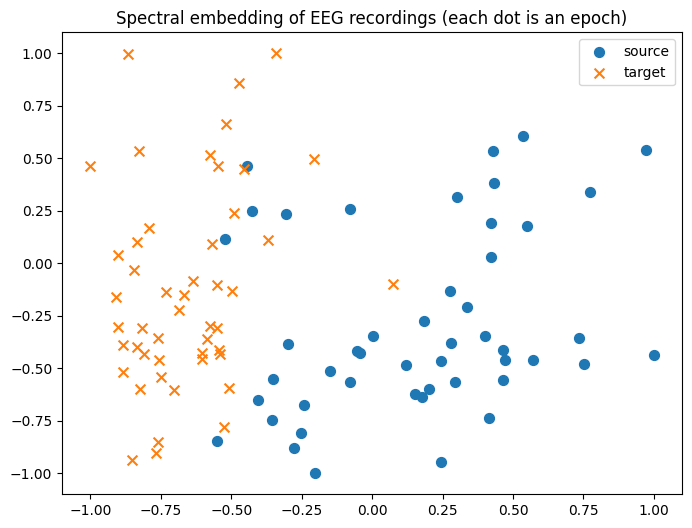

In [ ]:
dataset = BNCI2014_001()
paradigm = MotorImagery(n_classes=2)

# get all recordings from BNCI2014 database
recordings, labels, meta = paradigm.get_data(dataset=dataset, subjects=[2])
# define recordings that are source
sel_source = idx_source = (meta['run'] == "0") & (meta['session'] == "0train")
X_source, y_source = recordings[sel_source], labels[sel_source]
# define recordings that are target
sel_target = idx_target = (meta['run'] == "1") & (meta['session'] == "0train")
X_target, y_target = recordings[sel_target], labels[sel_target]
# concatenate recordings to make dataset
X = np.concatenate([X_source, X_target])
y = np.concatenate([y_source, y_target])
sample_domain = np.array(len(X_source)*[1] + len(X_target)*[-2])

y_converted = []
for yi in y:
    if yi == 'left_hand':
        y_converted.append(0)
    else:
        y_converted.append(1)
y = np.array(y_converted)
y[sample_domain < 0] = -1

C = Covariances(estimator='scm').fit_transform(X)
lapl = SpectralEmbedding(metric="riemann", n_components=2)
embd = lapl.fit_transform(X=C)

fig, ax = plt.subplots(figsize=(8, 6))

colors = {1: "C0", 2: "C1", 3: "C2"}
for i in range(len(C)):
    domain = 'source' if i < len(X_source) else 'target'
    color = 'C0' if domain == 'source' else 'C1'
    marker = 'o' if domain == 'source' else 'x'
    label = domain if i == 0 or i == len(X_source) else None
    ax.scatter(embd[i, 0], embd[i, 1], s=50, c=color, marker=marker, label=label)
ax.legend()
ax.set_title('Spectral embedding of EEG recordings (each dot is an epoch)')
plt.show()


In [94]:
from sklearn.model_selection import cross_val_score
from skada import make_da_pipeline, SelectSource
from skada.metrics import CircularValidation
from skada.model_selection import SourceTargetShuffleSplit
from pyriemann.tangentspace import TangentSpace
from sklearn.linear_model import LogisticRegression

pipeline = make_da_pipeline(
    Covariances(), TangentSpace(), LogisticRegression())
cv = SourceTargetShuffleSplit(n_splits=5, test_size=0.3, random_state=42)

scores_cv = cross_val_score(
    pipeline, X, y,
    params={'sample_domain': sample_domain},
    cv=cv,
    scoring=CircularValidation(),
)
print(f"Circular Validation score:  {scores_cv.mean():.3f}")

Circular Validation score:  0.500


/opt/homebrew/Caskroom/mambaforge/base/envs/datacamp/lib/python3.12/site-packages/skada/metrics.py:605: UserWarning: The predicted target domain labelsare all the same. 
  warnings.warn("The predicted target domain labels" "are all the same. ")
/opt/homebrew/Caskroom/mambaforge/base/envs/datacamp/lib/python3.12/site-packages/skada/metrics.py:605: UserWarning: The predicted target domain labelsare all the same. 
  warnings.warn("The predicted target domain labels" "are all the same. ")


In [95]:
pipeline = make_da_pipeline(
    Covariances(), TangentSpace(), OTMappingAdapter(), LogisticRegression())
cv = SourceTargetShuffleSplit(n_splits=5, test_size=0.3, random_state=42)

scores_cv = cross_val_score(
    pipeline, X, y,
    params={'sample_domain': sample_domain},
    cv=cv,
    scoring=CircularValidation(),
)
print(f"Circular Validation score:  {scores_cv.mean():.3f}")

/opt/homebrew/Caskroom/mambaforge/base/envs/datacamp/lib/python3.12/site-packages/skada/metrics.py:605: UserWarning: The predicted target domain labelsare all the same. 
  warnings.warn("The predicted target domain labels" "are all the same. ")


Circular Validation score:  0.567


We can also write our own adapters using the `skada` API.

In the `RiemannianRecenteringAdapter` below, we apply to each covariance matrix $C^{(d)}_i$ from domain $d$ the following operation:

$$\tilde{C}^{(d)}_i = M_d^{-1/2} \, C^{(d)}_i \, M_d^{-1/2}~,$$

where $M_d$ is the geometric mean of all matrices from that domain.

This ensures the transformed covariance matrices of each domain are centered around the Identity matrix. As for any other `skada` adapter, the domain of each matrix is given by `sample_domain`.

In [96]:
import numpy as np
from pyriemann.geometry.base import invsqrtm
from pyriemann.geometry.mean import gmean
from sklearn.utils.validation import check_is_fitted
from skada.base import BaseTestTimeAdapter
from skada.utils import check_X_domain, extract_domains_indices


class RiemannianRecenteringAdapter(BaseTestTimeAdapter):
    """Re-centers the SPD matrices of each domain to the identity [1]_.

    Parameters
    ----------
    metric : str, default="riemann"
        Metric used to estimate the mean of each domain, see
        :func:`pyriemann.geometry.mean.gmean`. Only the "riemann" metric
        re-centers the matrices exactly to the identity.
    auto_fit_new_domain : bool, default=False
        If True, the mean of a domain that was not seen during fit is
        estimated in `transform`, from the matrices of that domain, so they
        should all be given in the same call.

    Attributes
    ----------
    means_ : dict
        Mean of the matrices of each domain, indexed by domain label.

    References
    ----------
    .. [1] P. Zanini, M. Congedo, C. Jutten, S. Said and Y. Berthoumieu.
        "Transfer Learning: A Riemannian Geometry Framework With
        Applications to Brain-Computer Interfaces". IEEE Transactions on
        Biomedical Engineering, 65(5), 1107-1116, 2018.
    """

    def __init__(self, metric="riemann", auto_fit_new_domain=False):
        super().__init__(auto_fit_new_domain=auto_fit_new_domain)
        self.metric = metric

    def fit(self, X, y=None, *, sample_domain=None, **params):
        """Estimate the mean of each domain.

        Parameters
        ----------
        X : array-like, shape (n_samples, n_channels, n_channels)
            The SPD matrices (e.g. covariance matrices).
        y : array-like, shape (n_samples,)
            Ignored, the re-centering does not use the labels.
        sample_domain : array-like, shape (n_samples,)
            The domain labels.

        Returns
        -------
        self : object
            Returns self.
        """
        X, sample_domain = check_X_domain(X, sample_domain, allow_nd=True)
        self.means_ = {
            int(domain): gmean(X[idx], metric=self.metric)
            for domain, idx in extract_domains_indices(sample_domain).items()
        }
        return self

    def fit_new_domain(self, X, y=None, *, sample_domain=None, **params):
        """Estimate the mean of the domains that were not seen during fit.

        Parameters
        ----------
        X : array-like, shape (n_samples, n_channels, n_channels)
            The SPD matrices.
        y : array-like, shape (n_samples,)
            Ignored.
        sample_domain : array-like, shape (n_samples,)
            The domain labels.

        Returns
        -------
        self : object
            Returns self.
        """
        check_is_fitted(self)
        X, sample_domain = check_X_domain(X, sample_domain, allow_nd=True)
        for domain, idx in extract_domains_indices(sample_domain).items():
            if domain not in self.means_:
                self.means_[int(domain)] = gmean(X[idx], metric=self.metric)
        return self

    def fit_transform(self, X, y=None, *, sample_domain=None, **params):
        """Fit the adapter and re-center the matrices of every domain.

        Parameters
        ----------
        X : array-like, shape (n_samples, n_channels, n_channels)
            The SPD matrices.
        y : array-like, shape (n_samples,)
            Ignored.
        sample_domain : array-like, shape (n_samples,)
            The domain labels.

        Returns
        -------
        X_t : array-like, shape (n_samples, n_channels, n_channels)
            The re-centered matrices.
        """
        self.fit(X, y, sample_domain=sample_domain)
        return self.transform(
            X, sample_domain=sample_domain, allow_source=True
        )

    def transform(
        self, X, y=None, *, sample_domain=None, allow_source=False, **params
    ) -> np.ndarray:
        """Re-center the matrices of each domain with the mean of that domain.

        Parameters
        ----------
        X : array-like, shape (n_samples, n_channels, n_channels)
            The SPD matrices.
        y : array-like, shape (n_samples,)
            Ignored.
        sample_domain : array-like, shape (n_samples,)
            The domain labels.
        allow_source : bool, default=False
            If False, an error is raised when `X` contains source samples.
            Set it to True to re-center source matrices outside of fit.

        Returns
        -------
        X_t : array-like, shape (n_samples, n_channels, n_channels)
            The re-centered matrices.
        """
        check_is_fitted(self)
        X, sample_domain = check_X_domain(
            X, sample_domain, allow_source=allow_source, allow_nd=True
        )
        X_adapt = np.empty_like(X)
        for domain, idx in extract_domains_indices(sample_domain).items():
            if domain not in self.means_:
                if not self.auto_fit_new_domain:
                    raise ValueError(
                        f"Domain {domain} was not seen during fit. Pass the "
                        "same `sample_domain` labels as in fit, or set "
                        "`auto_fit_new_domain=True`."
                    )
                self.fit_new_domain(X[idx], sample_domain=sample_domain[idx])
            M_inv_sqrt = invsqrtm(self.means_[domain])
            X_adapt[idx] = M_inv_sqrt @ X[idx] @ M_inv_sqrt
        return X_adapt

In [99]:
pipeline = make_da_pipeline(
    Covariances(), RiemannianRecenteringAdapter(), SelectSource(MDM()))
cv = SourceTargetShuffleSplit(n_splits=5, test_size=0.3, random_state=42)

scores_cv = cross_val_score(
    pipeline, X, y,
    params={'sample_domain': sample_domain},
    cv=cv,
    scoring=CircularValidation(),
)
print(f"Circular Validation score:  {scores_cv.mean():.3f}")

Circular Validation score:  0.654
